# Computational Fluid Dynamics: Assignment 3 code reconstruction

This notebook ports the recoverable numerical work from the archived Assignment 3 bundle into Python. The available materials contain implementation listings and result plots, but not the complete assignment statement. The two test problems below are therefore identified from the code's right-hand sides and exact-solution formulas; treat those identifications as reconstructed, not as a substitute for the original prompt.

The original computational approach is retained: uniform one-dimensional grids, the Thomas tridiagonal solver, the archived variable-coefficient finite-difference coefficients, a conservative finite-volume stencil, and error studies. No alternative discretization is substituted.

## Problem 2: one-dimensional Poisson equation

The manufactured solution in the archived code is

$$u(x)=\frac{\sin(\beta\pi x)}{\beta^2\pi^2},\qquad 0\le x\le 1,$$

which satisfies $u''=-\sin(\beta\pi x)$ and $u(0)=u(1)=0$. With $N$ equal intervals and $h=1/N$, the interior equations are

$$u_{i-1}-2u_i+u_{i+1}=-h^2\sin(\beta\pi x_i).$$

They form a tridiagonal system solved by forward elimination and back substitution. The recorded error study uses $\beta=10$ and $N=25,50,100,200,400$. The saved comparison plot uses $N=50$ and $\beta=1,10,100$.

## Problem 3: discontinuous diffusion coefficient

From the exact formula and forcing encoded in the source, the model is reconstructed as

$$\frac{d}{dx}\left(\kappa(x)u'(x)\right)=-\sin(\pi x),\qquad u(0)=u(1)=0,$$

with $\kappa=1$ on the left half and $\kappa=m$ on the right half. The notebook implements both archived discretizations: the finite-difference coefficients as listed in the source and the face-averaged conservative finite-volume stencil. The piecewise exact solution used in the original error calculation is retained.

**Scope and uncertainty:** the full prompt and definitions of the reported error norms were not present in the inspected source bundle. The equations, boundary conditions, and error normalization here are inferred from the archived formulas; the RMS normalization follows the code's $\sqrt{\sum e_i^2/N}$.

## Runtime

Python 3 with NumPy and Matplotlib is sufficient. All numerical solvers and plots are implemented in this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def thomas_solve(lower, diagonal, upper, right_hand_side):
    """Solve a tridiagonal system by forward elimination and back substitution."""
    modified_diagonal = np.asarray(diagonal, dtype=float).copy()
    modified_rhs = np.asarray(right_hand_side, dtype=float).copy()
    lower = np.asarray(lower, dtype=float)
    upper = np.asarray(upper, dtype=float)

    for row in range(1, modified_rhs.size):
        elimination_factor = lower[row - 1] / modified_diagonal[row - 1]
        modified_diagonal[row] -= elimination_factor * upper[row - 1]
        modified_rhs[row] -= elimination_factor * modified_rhs[row - 1]

    solution = np.empty_like(modified_rhs)
    solution[-1] = modified_rhs[-1] / modified_diagonal[-1]
    for row in range(modified_rhs.size - 2, -1, -1):
        solution[row] = (
            modified_rhs[row] - upper[row] * solution[row + 1]
        ) / modified_diagonal[row]
    return solution


def poisson_dirichlet_solution(interval_count, wave_number):
    """Solve u''=-sin(k*pi*x), u(0)=u(1)=0, using the archived stencil."""
    step = 1.0 / interval_count
    interior_x = np.arange(1, interval_count) * step
    diagonal = -2.0 * np.ones(interval_count - 1)
    off_diagonal = np.ones(interval_count - 2)
    right_hand_side = -step**2 * np.sin(wave_number * np.pi * interior_x)
    numerical = thomas_solve(
        off_diagonal, diagonal, off_diagonal, right_hand_side
    )
    exact = np.sin(wave_number * np.pi * interior_x) / (
        wave_number**2 * np.pi**2
    )
    rms_error = np.sqrt(np.sum((numerical - exact) ** 2) / interval_count)
    maximum_error = np.max(np.abs(numerical - exact))
    return interior_x, numerical, exact, rms_error, maximum_error


def interface_exact_solution(x, contrast):
    """Piecewise exact solution encoded in the archived interface scripts."""
    x = np.asarray(x, dtype=float)
    exact = np.empty_like(x)
    left = x <= 0.5
    exact[left] = (
        np.sin(np.pi * x[left]) / np.pi**2
        + 2.0 * x[left] / np.pi**2 * (1.0 - contrast) / (1.0 + contrast)
    )
    exact[~left] = (
        np.sin(np.pi * x[~left]) / np.pi**2
        - 2.0 * (1.0 - x[~left]) / np.pi**2
        * (1.0 - contrast) / (1.0 + contrast)
    ) / contrast
    return exact


def interface_coefficients(interval_count, contrast, method):
    """Build the archived finite-difference or finite-volume tridiagonal system."""
    step = 1.0 / interval_count
    interior_count = interval_count - 1
    grid_kappa = np.where(
        np.arange(interval_count + 1) <= interval_count / 2.0,
        1.0,
        contrast,
    )
    diagonal = np.empty(interior_count)
    lower = np.empty(interior_count - 1)
    upper = np.empty(interior_count - 1)

    for interior_index in range(1, interval_count):
        row = interior_index - 1
        center = grid_kappa[interior_index]
        left = grid_kappa[interior_index - 1]
        right = grid_kappa[interior_index + 1]
        if method == "FD":
            diagonal[row] = -2.0 * center
            if row < interior_count - 1:
                upper[row] = center + (right - left) / 2.0
            if row > 0:
                lower[row - 1] = center - (right - left) / 2.0
        elif method == "FV":
            diagonal[row] = -(right + 2.0 * center + left) / 2.0
            if row < interior_count - 1:
                upper[row] = (right + center) / 2.0
            if row > 0:
                lower[row - 1] = (center + left) / 2.0
        else:
            raise ValueError(f"Unknown discretization: {method}")

    interior_x = np.arange(1, interval_count) * step
    right_hand_side = -step**2 * np.sin(np.pi * interior_x)
    return interior_x, lower, diagonal, upper, right_hand_side


def interface_solution(interval_count, contrast, method):
    interior_x, lower, diagonal, upper, right_hand_side = (
        interface_coefficients(interval_count, contrast, method)
    )
    numerical = thomas_solve(lower, diagonal, upper, right_hand_side)
    exact = interface_exact_solution(interior_x, contrast)
    rms_error = np.sqrt(
        np.sum((numerical - exact) ** 2) / interval_count
    )
    maximum_error = np.max(np.abs(numerical - exact))
    return interior_x, numerical, exact, rms_error, maximum_error


## Problem 2 results

Poisson Dirichlet problem, beta=10
 N       RMS error       maximum error
 25    1.02219e-04    1.37484e-04
 50    2.40429e-05    3.23376e-05
100    5.92175e-06    8.37462e-06
200    1.47496e-06    2.08591e-06
400    3.68398e-07    5.20994e-07
fitted RMS error order = 2.0259


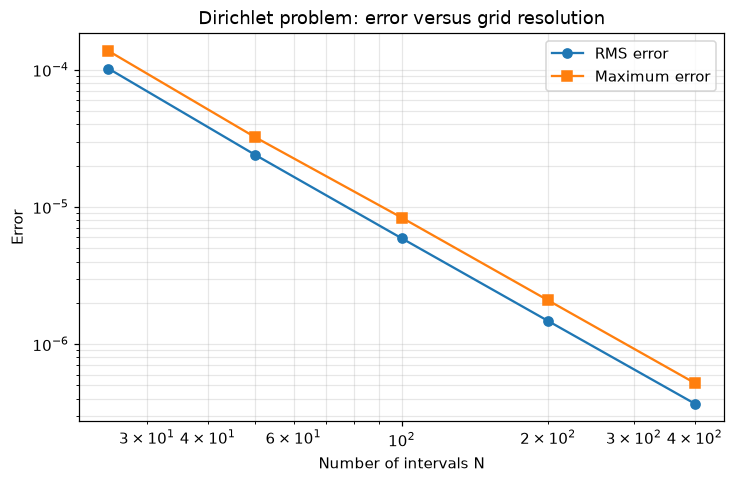

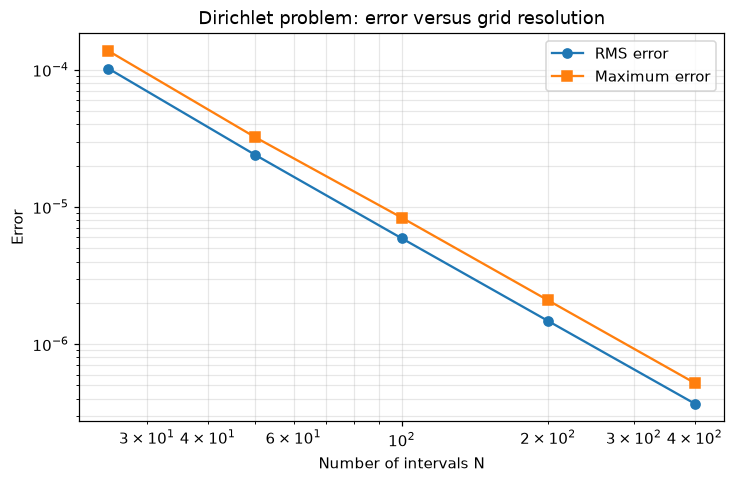

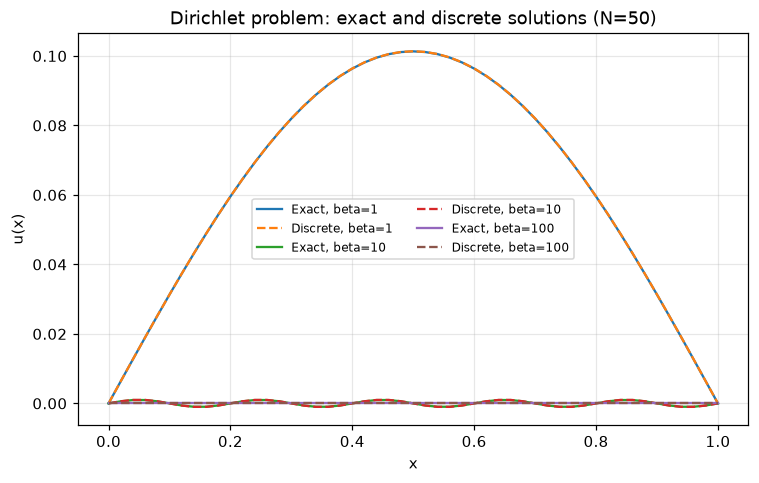

In [2]:
# The archived convergence script uses beta=10 and N=25,...,400.
interval_counts = np.array([25, 50, 100, 200, 400])
wave_number = 10
poisson_rms_errors = []
poisson_max_errors = []

for interval_count in interval_counts:
    _, _, _, rms_error, maximum_error = poisson_dirichlet_solution(
        interval_count, wave_number
    )
    poisson_rms_errors.append(rms_error)
    poisson_max_errors.append(maximum_error)

poisson_rms_errors = np.asarray(poisson_rms_errors)
poisson_max_errors = np.asarray(poisson_max_errors)
poisson_order = -np.polyfit(
    np.log(interval_counts), np.log(poisson_rms_errors), 1
)[0]
print("Poisson Dirichlet problem, beta=10")
print(" N       RMS error       maximum error")
for count, rms_error, maximum_error in zip(
    interval_counts, poisson_rms_errors, poisson_max_errors
):
    print(f"{count:3d}   {rms_error:12.5e}   {maximum_error:12.5e}")
print(f"fitted RMS error order = {poisson_order:.4f}")

figure, axes = plt.subplots(figsize=(6.8, 4.5))
axes.loglog(interval_counts, poisson_rms_errors, "o-", label="RMS error")
axes.loglog(interval_counts, poisson_max_errors, "s-", label="Maximum error")
axes.set(
    xlabel="Number of intervals N",
    ylabel="Error",
    title="Dirichlet problem: error versus grid resolution",
)
axes.grid(True, which="both", alpha=0.3)
axes.legend()
figure.tight_layout()
plt.show()

interval_count = 50
plot_x = np.linspace(0.0, 1.0, interval_count + 1)
figure, axes = plt.subplots(figsize=(7.0, 4.5))
for wave_number in (1, 10, 100):
    interior_x, numerical, exact, _, _ = poisson_dirichlet_solution(
        interval_count, wave_number
    )
    full_x = np.r_[0.0, interior_x, 1.0]
    full_numerical = np.r_[0.0, numerical, 0.0]
    full_exact = np.r_[0.0, exact, 0.0]
    axes.plot(full_x, full_exact, label=f"Exact, beta={wave_number}")
    axes.plot(
        full_x,
        full_numerical,
        "--",
        label=f"Discrete, beta={wave_number}",
    )
axes.set(
    xlabel="x",
    ylabel="u(x)",
    title="Dirichlet problem: exact and discrete solutions (N=50)",
)
axes.grid(True, alpha=0.3)
axes.legend(ncol=2, fontsize=8)
figure.tight_layout()
plt.show()


The $\beta=100$, $N=50$ comparison is a grid-alignment special case: $\sin(100\pi i/50)=0$ at every sampled interior node. Its sampled exact and discrete values are consequently zero and do not demonstrate resolution of the oscillatory continuous solution.

## Problem 3 results

Interface problem: RMS and maximum errors
method   contrast    N       RMS error       maximum error
  FD         10    25    2.16233e-02    3.99994e-02
  FD         10    50    2.15972e-02    3.82214e-02
  FD         10   100    2.15708e-02    3.78021e-02
  FD         10   200    2.15550e-02    3.75630e-02
  FD         10   400    2.15465e-02    3.74362e-02
  FV         10    25    8.46925e-04    2.00256e-03
  FV         10    50    1.15338e-04    2.66885e-04
  FV         10   100    5.41014e-05    1.28377e-04
  FV         10   200    2.61705e-05    6.29238e-05
  FV         10   400    1.28667e-05    3.11460e-05
  FV      10000    25    1.62648e-03    3.85043e-03
  FV      10000    50    3.70387e-06    7.26034e-06
  FV      10000   100    9.60939e-07    1.87273e-06
  FV      10000   200    2.58115e-07    4.97582e-07
  FV      10000   400    7.37450e-08    1.39553e-07


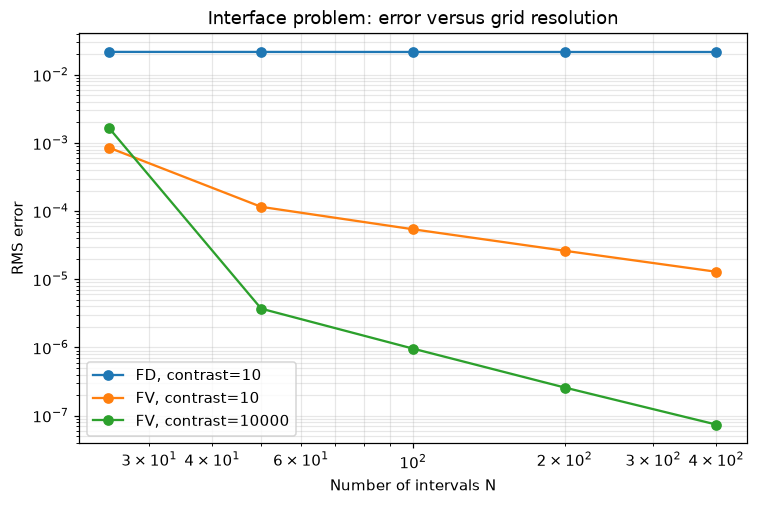

In [3]:
# Compare the two source discretizations at the recorded contrasts.
interval_counts = np.array([25, 50, 100, 200, 400])
study_cases = (("FD", 10), ("FV", 10), ("FV", 10000))
interface_errors = {}

for method, contrast in study_cases:
    rms_errors = []
    maximum_errors = []
    for interval_count in interval_counts:
        _, _, _, rms_error, maximum_error = interface_solution(
            interval_count, contrast, method
        )
        rms_errors.append(rms_error)
        maximum_errors.append(maximum_error)
    interface_errors[(method, contrast)] = (
        np.asarray(rms_errors),
        np.asarray(maximum_errors),
    )

print("Interface problem: RMS and maximum errors")
print("method   contrast    N       RMS error       maximum error")
for (method, contrast), (rms_errors, maximum_errors) in interface_errors.items():
    for count, rms_error, maximum_error in zip(
        interval_counts, rms_errors, maximum_errors
    ):
        print(
            f"{method:>4s}   {contrast:8g}   {count:3d}   "
            f"{rms_error:12.5e}   {maximum_error:12.5e}"
        )

figure, axes = plt.subplots(figsize=(7.0, 4.7))
for (method, contrast), (rms_errors, _) in interface_errors.items():
    axes.loglog(
        interval_counts,
        rms_errors,
        "o-",
        label=f"{method}, contrast={contrast:g}",
    )
axes.set(
    xlabel="Number of intervals N",
    ylabel="RMS error",
    title="Interface problem: error versus grid resolution",
)
axes.grid(True, which="both", alpha=0.3)
axes.legend()
figure.tight_layout()
plt.show()


## Numerical observations

For the constant-coefficient problem, the fitted RMS error rate is approximately second order, consistent with the centered second-difference stencil.

The finite-volume errors decrease under refinement for the recorded contrasts. The especially large change between the coarsest odd grid and the next grid at contrast $m=10000$ reflects the position of the discontinuous interface relative to the mesh and warrants care when interpreting a short convergence sequence.

The archived finite-difference variable-coefficient stencil does not approach the encoded piecewise exact solution in this reproduction: its RMS error levels off rather than decreasing. There is also a likely coefficient issue: a direct centered approximation of $(\kappa u')'$ yields off-diagonal derivative corrections of $\pm(\kappa_{i+1}-\kappa_{i-1})/4$ after scaling by $h^2$, while the archived coefficients use $\pm(\kappa_{i+1}-\kappa_{i-1})/2$. The notebook preserves the archived formula; confirm it against the missing assignment statement before changing the method.